# Preprocesamiento: detección automática por fotograma con YOLO26

Ejecuta **YOLO26** preentrenado (COCO) sobre cada fotograma de la fase `frames` y guarda, por fotograma:

- **Conteos** por clase: `n_pedestrian`, `n_car`, `n_bus`, `n_truck`, `n_motorcycle` y `n_vehiculos` (suma de vehículos).
- **Semáforos por color**: `n_traffic_light_red/yellow/green/unknown` y, con una heurística de tamaño y posición, `n_pedestrian_light_red/green`.

El código de inferencia y color está en `src/deteccion.py` (compartido con la pre-anotación de CVAT).

**Uso:** estos conteos alimentan los indicadores de `05_evaluation`. Las cajas para **entrenar** el detector NO salen de aquí: se pre-anotan y revisan por humanos en CVAT (`03_anotacion_cvat`), para evitar el entrenamiento circular.

**Salida:** `data/malaga/fases/detections.parquet` (fase `detections`), unida al resto por `(camera, image)`.

## 1. Configuración y modelo

In [1]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import pandas as pd
import torch
from ultralytics import YOLO

PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from config import load_config
from deteccion import frame_counts, predict_boxes
from pipeline import image_path, load_phase, save_phase

CFG = load_config()["deteccion"]
DEVICE = 0 if torch.cuda.is_available() else "cpu"

frames_df = load_phase("frames")
model = YOLO(CFG["modelo"])  # se descarga automáticamente la primera vez

print(f"Fotogramas: {len(frames_df)}")
print(f"Modelo: {CFG['modelo']} | conf={CFG['conf']} | imgsz={CFG['imgsz']} | dispositivo={DEVICE}")

Fotogramas: 74508
Modelo: yolo26s.pt | conf=0.25 | imgsz=640 | dispositivo=0


## 2. Detección sobre todos los fotogramas

Para una prueba rápida puede limitarse con `MAX_FRAMES` (None = todos).

In [2]:
MAX_FRAMES = None  # p.ej. 50 para una prueba rápida

work_df = frames_df if MAX_FRAMES is None else frames_df.head(MAX_FRAMES)

results = []
errors = []
for row in work_df.itertuples():
    img = cv2.imread(str(image_path(row.path)))
    if img is None:
        errors.append({"camera": row.camera, "image": row.image, "error": "no existe o no legible"})
        continue

    boxes = predict_boxes(model, img, conf=CFG["conf"], imgsz=CFG["imgsz"], device=DEVICE)
    results.append({
        "camera": row.camera,
        "image": row.image,
        **frame_counts(boxes, img.shape),
    })

    if len(results) % 500 == 0:
        print(f"Procesadas {len(results)} imágenes...")

detect_df = pd.DataFrame(results)
print(f"\nImágenes procesadas: {len(detect_df)} | errores: {len(errors)}")
if errors:
    display(pd.DataFrame(errors).head())
display(detect_df.head(10))

Procesadas 500 imágenes...


Procesadas 1000 imágenes...


Procesadas 1500 imágenes...


Procesadas 2000 imágenes...


Procesadas 2500 imágenes...


...

Procesadas 73500 imágenes...


Procesadas 74000 imágenes...



Imágenes procesadas: 74454 | errores: 54


,camera,image,error
0,21545,20260826T090850Z.jpg,no existe o no legible
1,21545,20261017T123926Z.jpg,no existe o no legible
2,21547,20260828T170426Z.jpg,no existe o no legible
3,21554,20261017T104002Z.jpg,no existe o no legible
4,21556,20260828T153325Z.jpg,no existe o no legible


,camera,image,n_pedestrian,n_car,n_bus,n_truck,n_motorcycle,n_traffic_light_red,n_traffic_light_yellow,n_traffic_light_green,n_traffic_light_unknown,n_pedestrian_light_red,n_pedestrian_light_green,n_vehiculos
0,21536,20261012T230457Z.jpg,1,0,0,0,0,0,0,0,0,0,0,0
1,21538,20261012T230623Z.jpg,0,1,0,1,0,0,0,0,2,0,0,2
2,21539,20261012T230624Z.jpg,0,0,0,0,0,0,1,0,0,0,0,0
3,21541,20260825T145146Z.jpg,0,3,1,2,0,0,0,0,4,0,0,6
4,21541,20260825T155429Z.jpg,0,5,0,0,0,0,0,0,3,0,0,5
5,21541,20260825T155459Z.jpg,1,7,0,1,1,0,0,0,3,0,0,9
6,21541,20260825T155529Z.jpg,0,5,0,1,1,0,0,0,3,0,0,7
7,21541,20260825T155559Z.jpg,0,3,0,1,0,0,0,0,2,0,0,4
8,21541,20260825T155629Z.jpg,0,5,0,1,0,0,0,0,1,0,0,6
9,21541,20260825T155659Z.jpg,0,5,0,1,0,0,0,0,3,0,0,6


## 3. Exportar la fase `detections`

In [3]:
out = save_phase(detect_df, "detections")
print(f"Fase detections: {len(detect_df)} fotogramas -> {out}")

count_cols = [c for c in detect_df.columns if c.startswith("n_")]
print("\nTotales y fotogramas con presencia por clase:")
display(pd.DataFrame({
    "total": detect_df[count_cols].sum(),
    "fotogramas_con_presencia": (detect_df[count_cols] > 0).sum(),
    "media_por_fotograma": detect_df[count_cols].mean().round(2),
}))

Fase detections: 74454 fotogramas -> C:\Users\loren\OneDrive\Escritorio\MASTER-UIMP\TFM\tfm\data\malaga\fases\detections.parquet

Totales y fotogramas con presencia por clase:


,total,fotogramas_con_presencia,media_por_fotograma
n_pedestrian,88032,28433,1.18
n_car,479189,66289,6.44
n_bus,31284,19640,0.42
n_truck,43272,25806,0.58
n_motorcycle,9257,6218,0.12
n_traffic_light_red,325,310,0.00
n_traffic_light_yellow,26642,14764,0.36
n_traffic_light_green,148,148,0.00
n_traffic_light_unknown,11155,8025,0.15
n_pedestrian_light_red,1397,1318,0.02


## 4. Visualización de muestras (opcional)

Dibuja las detecciones sobre algunas imágenes para validar visualmente la pre-anotación.

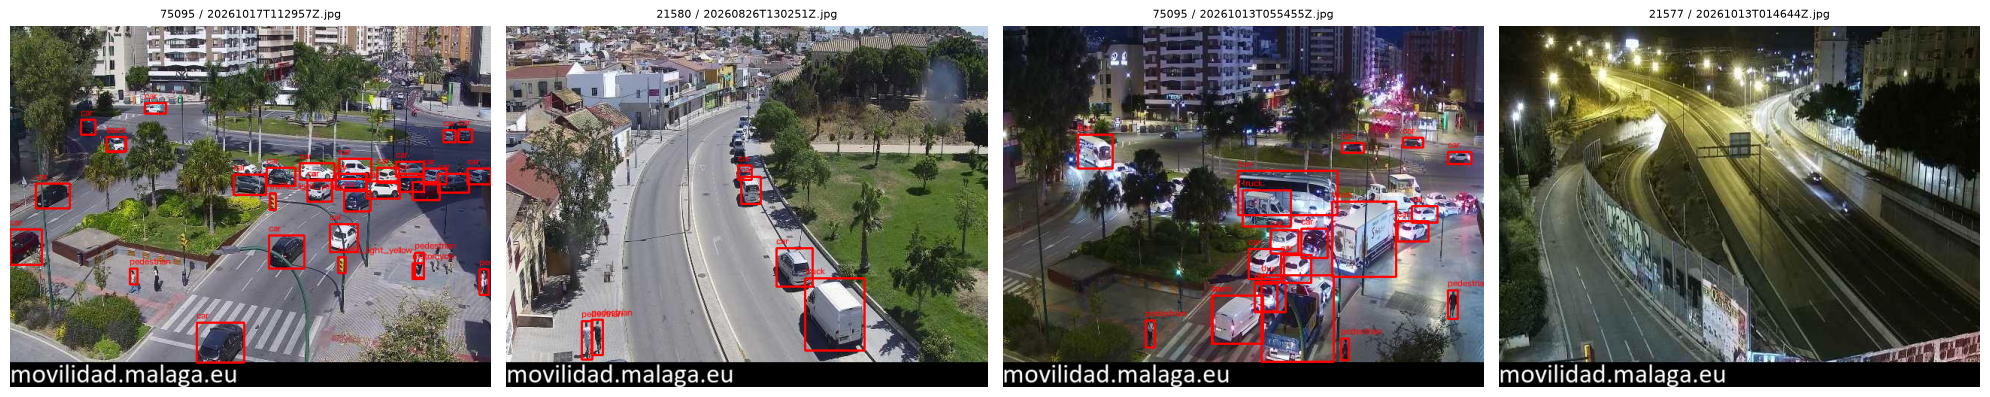

In [4]:
N_SAMPLES = 4

sample = frames_df.merge(detect_df[["camera", "image"]], on=["camera", "image"]).sample(
    min(N_SAMPLES, len(detect_df)), random_state=42
)
fig, axes = plt.subplots(1, len(sample), figsize=(5 * len(sample), 4), squeeze=False)

for ax, row in zip(axes[0], sample.itertuples()):
    img = cv2.imread(str(image_path(row.path)))
    for name, (x1, y1, x2, y2) in predict_boxes(model, img, conf=CFG["conf"], imgsz=CFG["imgsz"], device=DEVICE):
        cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), (0, 0, 255), 2)
        cv2.putText(img, name, (int(x1), max(0, int(y1) - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 0, 255), 1)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{row.camera} / {row.image}", fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()